# Student Academic Performance Analysis
### Mini Capstone Project | BCA (Hons. with Research) – AI & Data Science

**Submitted by:** MD Faiz Sheikh  
**Roll Number:** 2601201036  
**Course:** BCA (Hons. with Research) – AI & Data Science  
**University:** K.R. Mangalam University

**Objective:** Analyze student study hours, attendance, and subject marks using Python data analytics.

**Important:** This notebook creates a **synthetic sample dataset** automatically, so it runs in Google Colab without needing to upload a CSV first. It is not real student data. Confirm with your instructor whether synthetic data is allowed.

## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Create and load sample dataset

In [2]:
# Reproducible synthetic data for demonstration
rng = np.random.default_rng(42)
n = 120

study_hours = np.clip(rng.normal(2.8, 1.2, n), 0.3, 7.0).round(1)
attendance = np.clip(rng.normal(78, 12, n), 35, 100).round(1)
base = 35 + study_hours * 5.2 + attendance * 0.22 + rng.normal(0, 9, n)

df = pd.DataFrame({
    "Student_ID": [f"STU{i:03d}" for i in range(1, n + 1)],
    "Study_Hours_Per_Day": study_hours,
    "Attendance_Percent": attendance,
    "Maths_Marks": np.clip(base + rng.normal(0, 8, n), 12, 100).round().astype(int),
    "Python_Marks": np.clip(base + rng.normal(4, 7, n), 15, 100).round().astype(int),
    "Statistics_Marks": np.clip(base + rng.normal(-2, 9, n), 10, 100).round().astype(int),
    "English_Marks": np.clip(base + rng.normal(8, 6, n), 20, 100).round().astype(int)
})

# Add a few missing/invalid values so cleaning steps can be demonstrated
for col, count in [("Attendance_Percent", 4), ("Study_Hours_Per_Day", 3), ("Statistics_Marks", 3)]:
    missing_idx = rng.choice(n, size=count, replace=False)
    df.loc[missing_idx, col] = np.nan
df.loc[7, "Attendance_Percent"] = 145  # deliberately invalid attendance

print("Dataset created successfully.")
print("Rows and columns:", df.shape)
display(df.head())

Dataset created successfully.
Rows and columns: (120, 7)


,Student_ID,Study_Hours_Per_Day,Attendance_Percent,Maths_Marks,Python_Marks,Statistics_Marks,English_Marks
0,STU001,3.2,65.7,57,64,61.0,66
1,STU002,1.6,80.2,63,74,53.0,75
2,STU003,3.7,80.6,64,61,66.0,50
3,STU004,3.9,94.3,54,71,55.0,62
4,STU005,0.5,88.0,75,80,68.0,79


## 3. Inspect the dataset

In [3]:
print("Column names:")
print(df.columns.tolist())

print("\\nDataset information:")
df.info()

print("\\nMissing values in each column:")
display(df.isna().sum().to_frame("Missing_Count"))

print("\\nSummary statistics:")
display(df.describe().round(2))

Column names:
['Student_ID', 'Study_Hours_Per_Day', 'Attendance_Percent', 'Maths_Marks', 'Python_Marks', 'Statistics_Marks', 'English_Marks']
\nDataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Student_ID           120 non-null    object 
 1   Study_Hours_Per_Day  117 non-null    float64
 2   Attendance_Percent   116 non-null    float64
 3   Maths_Marks          120 non-null    int64  
 4   Python_Marks         120 non-null    int64  
 5   Statistics_Marks     117 non-null    float64
 6   English_Marks        120 non-null    int64  
dtypes: float64(3), int64(3), object(1)
memory usage: 6.7+ KB
\nMissing values in each column:


,Missing_Count
Student_ID,0
Study_Hours_Per_Day,3
Attendance_Percent,4
Maths_Marks,0
Python_Marks,0
Statistics_Marks,3
English_Marks,0


\nSummary statistics:


,Study_Hours_Per_Day,Attendance_Percent,Maths_Marks,Python_Marks,Statistics_Marks,English_Marks
count,117.00,116.00,120.00,120.00,117.00,120.00
mean,2.74,78.31,66.72,70.22,63.68,74.83
std,0.95,13.16,11.63,12.26,12.79,11.83
min,0.50,52.20,43.00,30.00,26.00,48.00
25%,2.20,69.30,57.75,64.00,54.00,66.75
50%,2.70,77.40,66.00,71.00,64.00,74.50
75%,3.40,85.62,75.00,80.00,72.00,83.25
max,5.40,145.00,93.00,96.00,92.00,100.00


## 4. Clean the data

In [4]:
clean_df = df.copy()

# Remove duplicate rows
duplicate_count = int(clean_df.duplicated().sum())
clean_df = clean_df.drop_duplicates()

# Attendance percentage must be between 0 and 100
invalid_attendance = (
    (clean_df["Attendance_Percent"] < 0) |
    (clean_df["Attendance_Percent"] > 100)
)
print("Duplicate rows removed:", duplicate_count)
print("Invalid attendance values corrected:", int(invalid_attendance.sum()))
clean_df.loc[invalid_attendance, "Attendance_Percent"] = np.nan

# Replace missing numeric values with each column's median
numeric_cols = clean_df.select_dtypes(include="number").columns
for col in numeric_cols:
    clean_df[col] = clean_df[col].fillna(clean_df[col].median())

print("\\nMissing values after cleaning:")
display(clean_df.isna().sum().to_frame("Missing_After_Cleaning"))

Duplicate rows removed: 0
Invalid attendance values corrected: 1
\nMissing values after cleaning:


,Missing_After_Cleaning
Student_ID,0
Study_Hours_Per_Day,0
Attendance_Percent,0
Maths_Marks,0
Python_Marks,0
Statistics_Marks,0
English_Marks,0


## 5. Feature engineering

In [5]:
subject_cols = ["Maths_Marks", "Python_Marks", "Statistics_Marks", "English_Marks"]

clean_df["Total_Marks"] = clean_df[subject_cols].sum(axis=1)
clean_df["Average_Marks"] = clean_df[subject_cols].mean(axis=1).round(2)
clean_df["Percentage"] = clean_df["Average_Marks"].round(2)

clean_df["Attendance_Category"] = pd.cut(
    clean_df["Attendance_Percent"],
    bins=[-0.001, 60, 80, 100],
    labels=["Low", "Moderate", "High"],
    include_lowest=True
)

clean_df["Performance_Category"] = pd.cut(
    clean_df["Percentage"],
    bins=[-0.001, 50, 75, 100],
    labels=["Needs Improvement", "Good", "Excellent"],
    include_lowest=True
)

display(clean_df.head())

,Student_ID,Study_Hours_Per_Day,Attendance_Percent,Maths_Marks,Python_Marks,Statistics_Marks,English_Marks,Total_Marks,Average_Marks,Percentage,Attendance_Category,Performance_Category
0,STU001,3.2,65.7,57,64,61.0,66,248.0,62.00,62.00,Moderate,Good
1,STU002,1.6,80.2,63,74,53.0,75,265.0,66.25,66.25,High,Good
2,STU003,3.7,80.6,64,61,66.0,50,241.0,60.25,60.25,High,Good
3,STU004,3.9,94.3,54,71,55.0,62,242.0,60.50,60.50,High,Good
4,STU005,0.5,88.0,75,80,68.0,79,302.0,75.50,75.50,High,Excellent


## 6. Outlier detection using IQR

In [6]:
def iqr_summary(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    count = int(((series < lower_bound) | (series > upper_bound)).sum())
    return pd.Series({
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": count
    })

outlier_cols = ["Study_Hours_Per_Day", "Attendance_Percent"] + subject_cols
outlier_table = pd.DataFrame({col: iqr_summary(clean_df[col]) for col in outlier_cols}).T
display(outlier_table.round(2))
print("Note: IQR flags unusual values for review; it does not automatically mean they are errors.")

,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count
Study_Hours_Per_Day,2.20,3.40,1.20,0.40,5.20,1.0
Attendance_Percent,69.52,83.68,14.15,48.30,104.90,0.0
Maths_Marks,57.75,75.00,17.25,31.88,100.88,0.0
Python_Marks,64.00,80.00,16.00,40.00,104.00,2.0
Statistics_Marks,54.00,72.00,18.00,27.00,99.00,1.0
English_Marks,66.75,83.25,16.50,42.00,108.00,0.0


Note: IQR flags unusual values for review; it does not automatically mean they are errors.


## 7. Visualizations

### 7.1 Average marks by subject

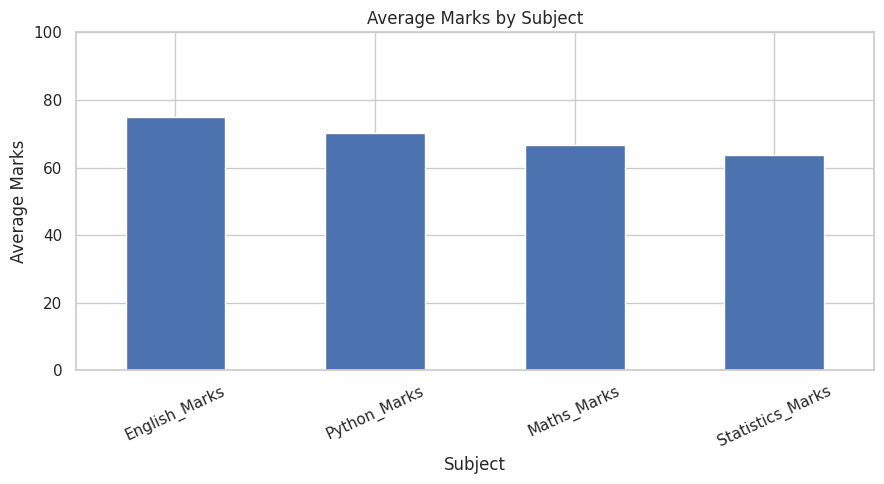

In [7]:
subject_means = clean_df[subject_cols].mean().sort_values(ascending=False)
ax = subject_means.plot(kind="bar", title="Average Marks by Subject",
                        ylabel="Average Marks", xlabel="Subject", rot=25)
ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()

### 7.2 Distribution of average marks

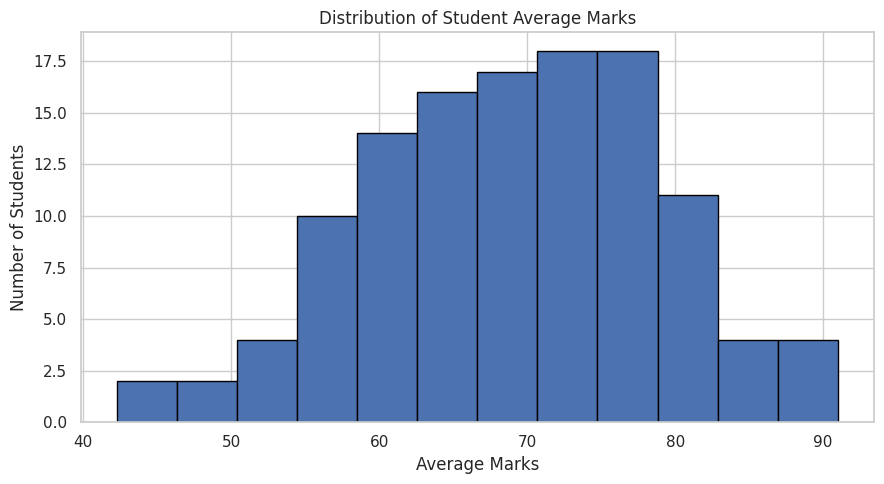

In [8]:
plt.figure()
plt.hist(clean_df["Average_Marks"], bins=12, edgecolor="black")
plt.title("Distribution of Student Average Marks")
plt.xlabel("Average Marks")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

### 7.3 Study hours vs average marks

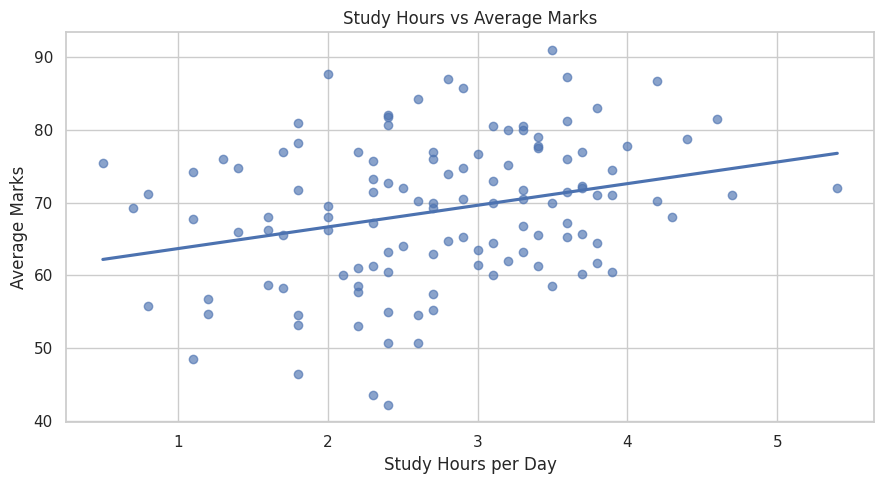

In [9]:
plt.figure()
sns.regplot(data=clean_df, x="Study_Hours_Per_Day", y="Average_Marks",
            scatter_kws={"alpha": 0.65}, ci=None)
plt.title("Study Hours vs Average Marks")
plt.xlabel("Study Hours per Day")
plt.ylabel("Average Marks")
plt.tight_layout()
plt.show()

### 7.4 Attendance vs average marks

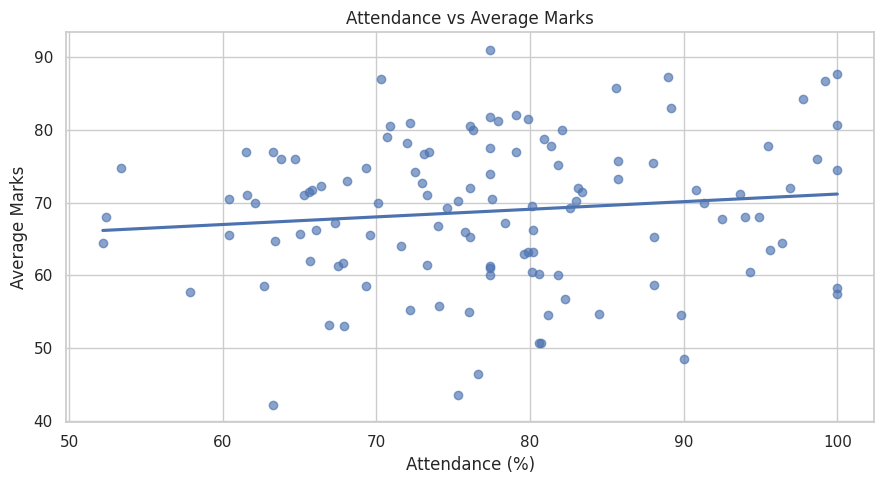

In [10]:
plt.figure()
sns.regplot(data=clean_df, x="Attendance_Percent", y="Average_Marks",
            scatter_kws={"alpha": 0.65}, ci=None)
plt.title("Attendance vs Average Marks")
plt.xlabel("Attendance (%)")
plt.ylabel("Average Marks")
plt.tight_layout()
plt.show()

### 7.5 Correlation heatmap

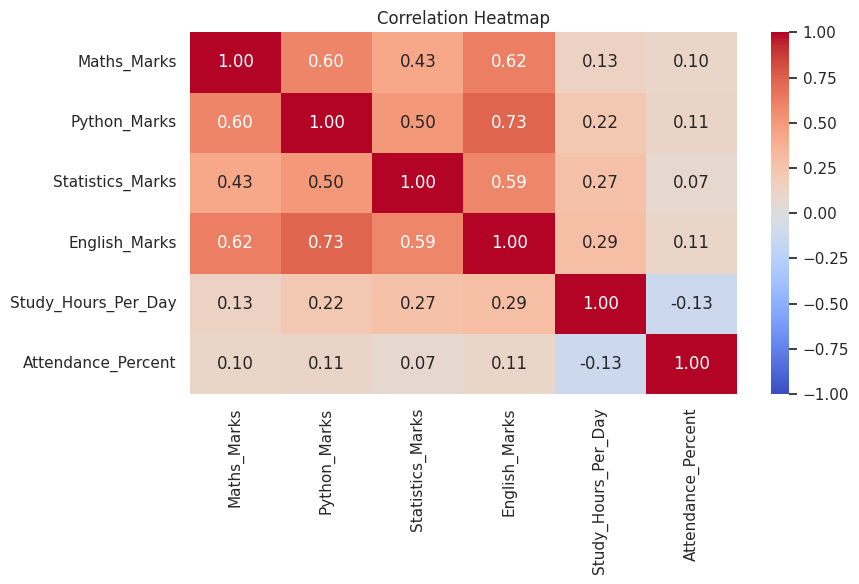

In [11]:
corr_cols = subject_cols + ["Study_Hours_Per_Day", "Attendance_Percent"]
corr = clean_df[corr_cols].corr(numeric_only=True)

plt.figure(figsize=(9, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

### 7.6 Students by performance category

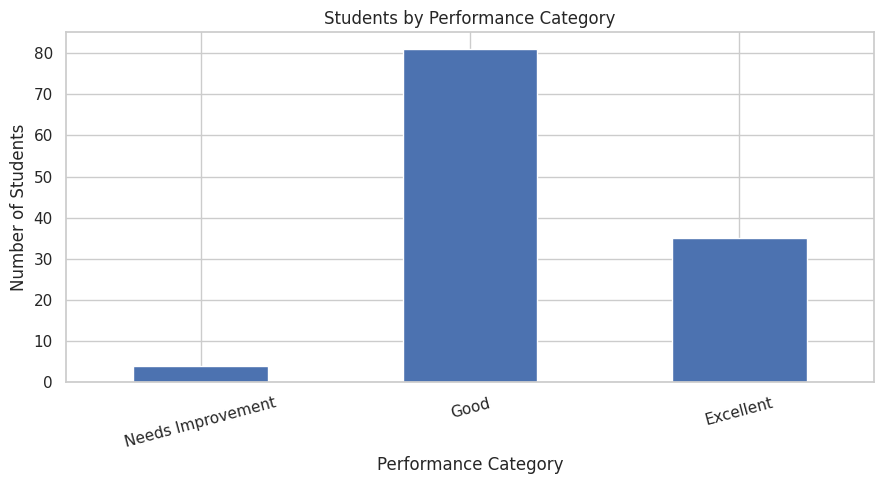

,Student_Count
Performance_Category,
Needs Improvement,4
Good,81
Excellent,35


In [12]:
category_order = ["Needs Improvement", "Good", "Excellent"]
category_counts = clean_df["Performance_Category"].value_counts().reindex(category_order, fill_value=0)

ax = category_counts.plot(kind="bar", title="Students by Performance Category",
                          ylabel="Number of Students", xlabel="Performance Category", rot=15)
plt.tight_layout()
plt.show()

display(category_counts.to_frame("Student_Count"))

### 7.7 Average marks by attendance category

,Mean_Average_Marks
Attendance_Category,
Low,66.25
Moderate,68.95
High,68.96


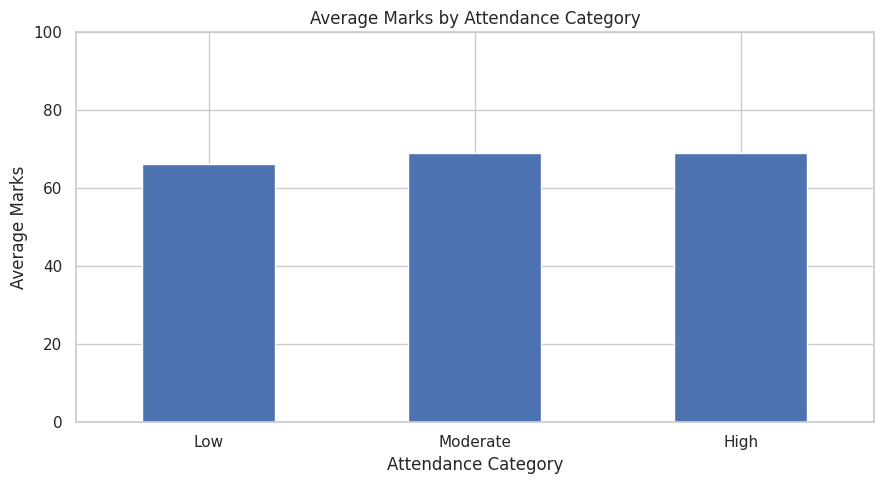

In [13]:
attendance_summary = clean_df.groupby("Attendance_Category", observed=False)["Average_Marks"].mean()
display(attendance_summary.round(2).to_frame("Mean_Average_Marks"))

ax = attendance_summary.plot(kind="bar", title="Average Marks by Attendance Category",
                             ylabel="Average Marks", xlabel="Attendance Category", rot=0)
ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()

## 8. Summary and key findings

In [14]:
print("Subject-wise statistics:")
display(clean_df[subject_cols].agg(["mean", "median", "min", "max"]).T.round(2))

print("Performance category distribution (%):")
display((clean_df["Performance_Category"].value_counts(normalize=True) * 100)
        .round(1).to_frame("Percent_of_Students"))

best_subject = clean_df[subject_cols].mean().idxmax().replace("_Marks", "")
lowest_subject = clean_df[subject_cols].mean().idxmin().replace("_Marks", "")
attendance_corr = clean_df["Attendance_Percent"].corr(clean_df["Average_Marks"])
study_corr = clean_df["Study_Hours_Per_Day"].corr(clean_df["Average_Marks"])

print(f"Number of student records: {len(clean_df)}")
print(f"Highest average subject: {best_subject}")
print(f"Lowest average subject: {lowest_subject}")
print(f"Mean attendance: {clean_df['Attendance_Percent'].mean():.2f}%")
print(f"Mean study hours per day: {clean_df['Study_Hours_Per_Day'].mean():.2f}")
print(f"Correlation (attendance, average marks): {attendance_corr:.2f}")
print(f"Correlation (study hours, average marks): {study_corr:.2f}")
print("Interpretation: correlations describe association and do not prove cause and effect.")

Subject-wise statistics:


,mean,median,min,max
Maths_Marks,66.72,66.0,43.0,93.0
Python_Marks,70.22,71.0,30.0,96.0
Statistics_Marks,63.68,64.0,26.0,92.0
English_Marks,74.83,74.5,48.0,100.0


Performance category distribution (%):


,Percent_of_Students
Performance_Category,
Good,67.5
Excellent,29.2
Needs Improvement,3.3


Number of student records: 120
Highest average subject: English
Lowest average subject: Statistics
Mean attendance: 77.72%
Mean study hours per day: 2.74
Correlation (attendance, average marks): 0.12
Correlation (study hours, average marks): 0.28
Interpretation: correlations describe association and do not prove cause and effect.


## 9. Conclusion
This project demonstrates data inspection, data cleaning, feature engineering, IQR-based outlier detection, exploratory data analysis, visualization, and interpretation.

## 10. Limitations
- The dataset is synthetic and is only for demonstration.
- Only a small number of variables are included.
- This is descriptive analysis, not a machine-learning prediction system.

## 11. Future scope
- Use an instructor-approved dataset with privacy safeguards.
- Add other relevant variables if permitted.
- Build an interactive dashboard using Streamlit or Power BI.
- Consider machine learning only if a clear prediction objective and suitable data are available.

## 12. Viva questions
1. What is data cleaning?
2. Why is median used to fill missing values?
3. What is feature engineering?
4. Explain the IQR method.
5. What does a correlation coefficient represent?
6. Why does correlation not imply causation?
7. What are the limitations of this project?